# Practical 2: Interacting with Web APIs

** Analyzing Weather Data from OpenWeatherMap API
To retrieve weather data from the OpenWeatherMap API for a selected city, extract useful weather attributes, preprocess and analyze the data, and visualize weather patterns.


In [ ]:
%pip install requests pandas numpy matplotlib seaborn

In [1]:
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from getpass import getpass

In [2]:
# Get your API key from https://openweathermap.org/api
API_KEY = getpass("Enter your OpenWeatherMap API key: ")
CITY = input("Enter city name (e.g., Pune): ").strip()

print("City selected:", CITY)

City selected: Pune


In [3]:
url = "https://api.openweathermap.org/data/2.5/forecast"
params = {"q": CITY, "appid": API_KEY, "units": "metric"}

response = requests.get(url, params=params, timeout=30)

if response.status_code == 200:
    weather_data = response.json()
    print("Weather data retrieved successfully.")
    print("City:", weather_data["city"]["name"])
    print("Country:", weather_data["city"]["country"])
else:
    print("API request failed.")
    print("Status code:", response.status_code)
    print("Message:", response.text)
    raise RuntimeError("Check your API key, city name, internet connection, and API access.")

Weather data retrieved successfully.
City: Pune
Country: IN


In [4]:
records = []

for item in weather_data["list"]:
    records.append({
        "Date_Time": item["dt_txt"],
        "Temperature": item["main"].get("temp"),
        "Feels_Like": item["main"].get("feels_like"),
        "Humidity": item["main"].get("humidity"),
        "Pressure": item["main"].get("pressure"),
        "Wind_Speed": item.get("wind", {}).get("speed"),
        "Weather": item["weather"][0].get("description"),
        "Rain": item.get("rain", {}).get("3h", 0),
        "Latitude": weather_data["city"]["coord"].get("lat"),
        "Longitude": weather_data["city"]["coord"].get("lon")
    })

df = pd.DataFrame(records)
display(df.head())

,Date_Time,Temperature,Feels_Like,Humidity,Pressure,Wind_Speed,Weather,Rain,Latitude,Longitude
0,2026-11-01 15:00:00,27.04,29.64,78,1015,1.00,light rain,1.42,18.5196,73.8553
1,2026-11-01 18:00:00,26.77,29.16,79,1015,0.50,light rain,0.22,18.5196,73.8553
2,2026-11-01 21:00:00,25.78,26.55,82,1014,1.39,light rain,1.37,18.5196,73.8553
3,2026-11-02 00:00:00,25.33,26.09,83,1014,2.73,moderate rain,3.82,18.5196,73.8553
4,2026-11-02 03:00:00,23.91,24.63,87,1017,2.17,light rain,0.56,18.5196,73.8553


In [5]:
print("Dataset shape:", df.shape)
print("\nDataset information:")
df.info()
print("\nStatistical summary:")
display(df.describe())
print("\nFirst five records:")
display(df.head())

Dataset shape: (40, 10)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40 entries, 0 to 39
Data columns (total 10 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Date_Time    40 non-null     object 
 1   Temperature  40 non-null     float64
 2   Feels_Like   40 non-null     float64
 3   Humidity     40 non-null     int64  
 4   Pressure     40 non-null     int64  
 5   Wind_Speed   40 non-null     float64
 6   Weather      40 non-null     object 
 7   Rain         40 non-null     float64
 8   Latitude     40 non-null     float64
 9   Longitude    40 non-null     float64
dtypes: float64(6), int64(2), object(2)
memory usage: 3.3+ KB

Statistical summary:


,Temperature,Feels_Like,Humidity,Pressure,Wind_Speed,Rain,Latitude,Longitude
count,40.000000,40.000000,40.000000,40.000000,40.000000,40.00000,40.0000,40.0000
mean,26.486500,27.298250,65.150000,1014.500000,1.824500,0.51850,18.5196,73.8553
std,2.452652,2.801799,13.525948,1.339728,1.064362,0.97655,0.0000,0.0000
min,22.370000,22.440000,36.000000,1012.000000,0.100000,0.00000,18.5196,73.8553
25%,24.892500,25.150000,55.750000,1013.000000,0.997500,0.00000,18.5196,73.8553
50%,26.460000,27.150000,64.000000,1015.000000,1.690000,0.05000,18.5196,73.8553
75%,28.337500,29.827500,76.500000,1015.000000,2.450000,0.57500,18.5196,73.8553
max,31.150000,32.820000,87.000000,1017.000000,4.350000,3.82000,18.5196,73.8553



First five records:


,Date_Time,Temperature,Feels_Like,Humidity,Pressure,Wind_Speed,Weather,Rain,Latitude,Longitude
0,2026-11-01 15:00:00,27.04,29.64,78,1015,1.00,light rain,1.42,18.5196,73.8553
1,2026-11-01 18:00:00,26.77,29.16,79,1015,0.50,light rain,0.22,18.5196,73.8553
2,2026-11-01 21:00:00,25.78,26.55,82,1014,1.39,light rain,1.37,18.5196,73.8553
3,2026-11-02 00:00:00,25.33,26.09,83,1014,2.73,moderate rain,3.82,18.5196,73.8553
4,2026-11-02 03:00:00,23.91,24.63,87,1017,2.17,light rain,0.56,18.5196,73.8553


In [6]:
df["Date_Time"] = pd.to_datetime(df["Date_Time"], errors="coerce")

numeric_cols = ["Temperature", "Feels_Like", "Humidity", "Pressure",
                "Wind_Speed", "Rain", "Latitude", "Longitude"]
for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df = df.drop_duplicates()

for col in numeric_cols:
    df[col] = df[col].fillna(df[col].mean())

df = df.dropna(subset=["Date_Time"])
df = df.sort_values("Date_Time").reset_index(drop=True)

print("Data cleaning completed.")
print("Missing values after cleaning:")
display(df.isnull().sum())
display(df.head())

Data cleaning completed.
Missing values after cleaning:


Date_Time      0
Temperature    0
Feels_Like     0
Humidity       0
Pressure       0
Wind_Speed     0
Weather        0
Rain           0
Latitude       0
Longitude      0
dtype: int64

,Date_Time,Temperature,Feels_Like,Humidity,Pressure,Wind_Speed,Weather,Rain,Latitude,Longitude
0,2026-11-01 15:00:00,27.04,29.64,78,1015,1.00,light rain,1.42,18.5196,73.8553
1,2026-11-01 18:00:00,26.77,29.16,79,1015,0.50,light rain,0.22,18.5196,73.8553
2,2026-11-01 21:00:00,25.78,26.55,82,1014,1.39,light rain,1.37,18.5196,73.8553
3,2026-11-02 00:00:00,25.33,26.09,83,1014,2.73,moderate rain,3.82,18.5196,73.8553
4,2026-11-02 03:00:00,23.91,24.63,87,1017,2.17,light rain,0.56,18.5196,73.8553


In [7]:
print("Average Temperature:", round(df["Temperature"].mean(), 2), "°C")
print("Maximum Temperature:", round(df["Temperature"].max(), 2), "°C")
print("Minimum Temperature:", round(df["Temperature"].min(), 2), "°C")
print("Average Humidity:", round(df["Humidity"].mean(), 2), "%")
print("Average Wind Speed:", round(df["Wind_Speed"].mean(), 2), "m/s")
print("Total Forecast Rainfall:", round(df["Rain"].sum(), 2), "mm")

Average Temperature: 26.49 °C
Maximum Temperature: 31.15 °C
Minimum Temperature: 22.37 °C
Average Humidity: 65.15 %
Average Wind Speed: 1.82 m/s
Total Forecast Rainfall: 20.74 mm


In [8]:
df["Date"] = df["Date_Time"].dt.date

daily_weather = df.groupby("Date").agg(
    Average_Temperature=("Temperature", "mean"),
    Maximum_Temperature=("Temperature", "max"),
    Minimum_Temperature=("Temperature", "min"),
    Average_Humidity=("Humidity", "mean"),
    Average_Wind_Speed=("Wind_Speed", "mean"),
    Total_Rainfall=("Rain", "sum")
).reset_index()

display(daily_weather)

,Date,Average_Temperature,Maximum_Temperature,Minimum_Temperature,Average_Humidity,Average_Wind_Speed,Total_Rainfall
0,2026-11-01,26.53000,27.04,25.78,79.666667,0.963333,3.01
1,2026-11-02,26.76250,31.12,23.91,75.250000,2.053750,13.23
2,2026-11-03,25.79375,28.62,22.76,70.875000,1.498750,3.56
3,2026-11-04,26.37250,30.38,22.37,61.500000,1.587500,0.94
4,2026-11-05,26.53500,30.71,22.80,56.375000,2.103750,0.00
5,2026-11-06,27.23200,31.15,22.51,51.000000,2.428000,0.00


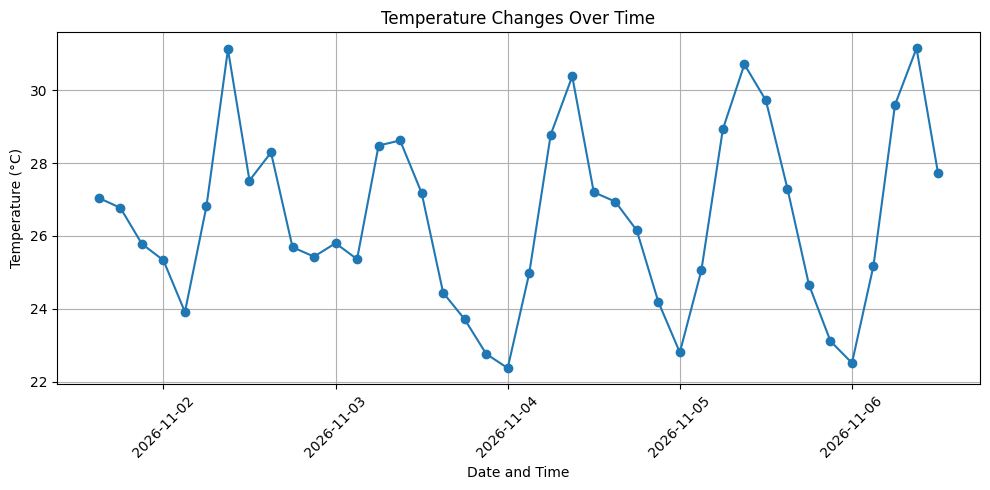

In [9]:
plt.figure(figsize=(10, 5))
plt.plot(df["Date_Time"], df["Temperature"], marker="o")
plt.title("Temperature Changes Over Time")
plt.xlabel("Date and Time")
plt.ylabel("Temperature (°C)")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

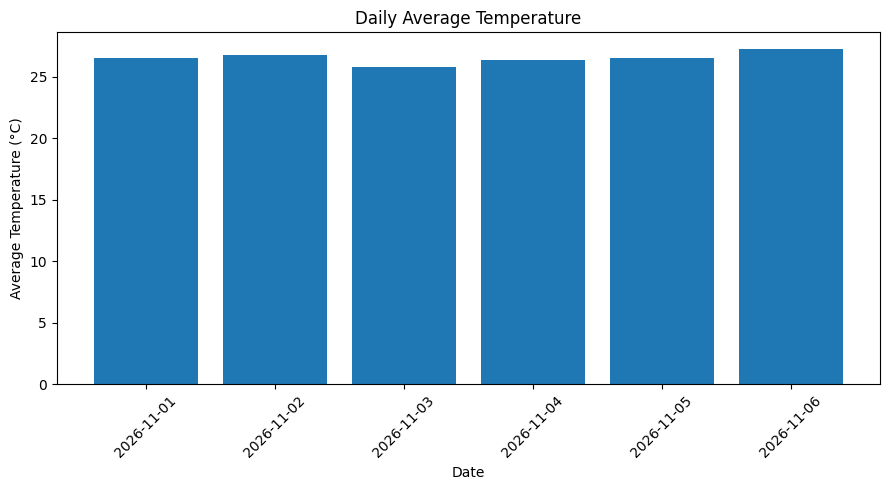

In [10]:
plt.figure(figsize=(9, 5))
plt.bar(daily_weather["Date"].astype(str), daily_weather["Average_Temperature"])
plt.title("Daily Average Temperature")
plt.xlabel("Date")
plt.ylabel("Average Temperature (°C)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

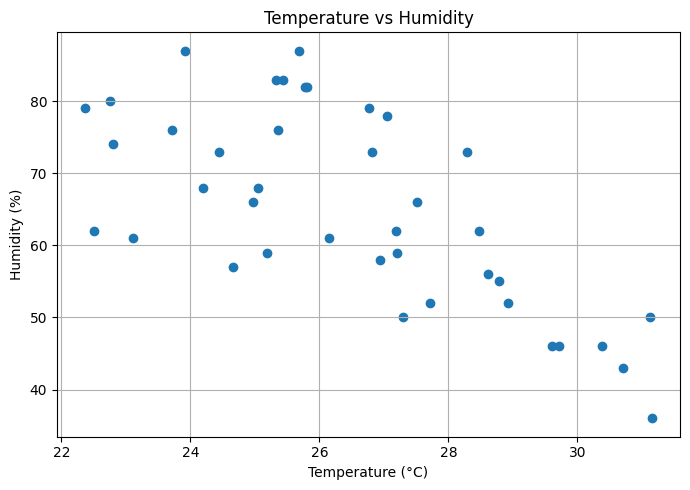

In [11]:
plt.figure(figsize=(7, 5))
plt.scatter(df["Temperature"], df["Humidity"])
plt.title("Temperature vs Humidity")
plt.xlabel("Temperature (°C)")
plt.ylabel("Humidity (%)")
plt.grid(True)
plt.tight_layout()
plt.show()

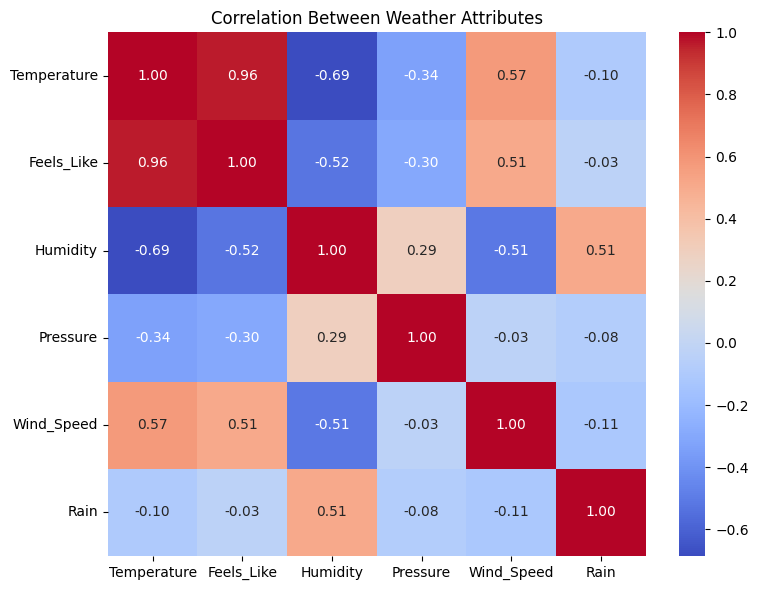

In [12]:
correlation = df[["Temperature", "Feels_Like", "Humidity",
                    "Pressure", "Wind_Speed", "Rain"]].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(correlation, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Between Weather Attributes")
plt.tight_layout()
plt.show()

In [13]:
latitude = df["Latitude"].iloc[0]
longitude = df["Longitude"].iloc[0]

print("City:", weather_data["city"]["name"])
print("Latitude:", latitude)
print("Longitude:", longitude)

City: Pune
Latitude: 18.5196
Longitude: 73.8553
